# 03 - Interpretation

What is the chosen model (the ensemble: Ridge + splines averaged with gradient
boosting) actually doing?

1. **Which features matter**: permutation importance, per feature and per group
2. **What shape each effect has**: partial dependence curves
3. **Does the minutes effect depend on the pick?** (interaction)
4. **Player stories**: where the model corrected the pick, and where it still missed
5. **Bias checks**: systematic errors by era, age or segment

Everything uses the development set (classes 2000-2013) and out-of-fold
predictions: each player is judged by models that never saw him. The model
definitions live in `src/models.py`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import partial_dependence
from sklearn.model_selection import GroupKFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import modelling as m
import models as md
from plot_style import apply_style, BLUE, ORANGE, AQUA, NEUTRAL, INK_2

apply_style()
dev = m.dev_set(md.add_pick_terms(m.load_table()))
dev[md.ALL] = dev[md.ALL].astype(float)  # partial dependence needs float columns

# Out-of-fold predictions (5 repeats x 5 folds), same as in 02_modelling
model_folds, model_oof = m.repeated_cv(md.ensemble, md.ALL, dev)
base_folds, base_oof = m.repeated_cv(md.baseline, ["pick"], dev)
print(f"Development set: {len(dev)} players")
print(f"Repeated-CV RMSE - ensemble: {model_folds['rmse'].mean():.3f}, "
      f"baseline: {base_folds['rmse'].mean():.3f}")

Development set: 683 players
Repeated-CV RMSE - ensemble: 1.889, baseline: 2.102


## 1. Which features matter? (permutation importance)

For each validation fold: fit the model on the other folds, then **shuffle one
feature** in the validation fold and measure how much the RMSE gets worse. If
shuffling a feature barely hurts, the model wasn't relying on it.

Features that carry the same information (minutes per game, games played,
total minutes) *share* importance: shuffle one and the model leans on the
others, so each looks less important alone than the group really is. That's why
whole **groups** are also shuffled together.

In [2]:
def rmse(y, p):
    return float(np.sqrt(np.mean((y - p) ** 2)))


def permutation_importance_cv(column_sets, repeats=3, n_shuffles=5, seed=0):
    """RMSE increase when each column set is shuffled, on held-out folds."""
    rng = np.random.default_rng(seed)
    rows = []
    for r in range(repeats):
        folds = GroupKFold(n_splits=m.N_FOLDS, shuffle=True, random_state=r)
        for tr, va in folds.split(dev, groups=dev["draft_year"]):
            model = md.ensemble().fit(dev.iloc[tr][md.ALL], dev.iloc[tr][m.TARGET])
            X = dev.iloc[va][md.ALL]
            y = dev.iloc[va][m.TARGET].to_numpy()
            reference = rmse(y, model.predict(X))
            for name, cols in column_sets.items():
                for _ in range(n_shuffles):
                    shuffled = X.copy()
                    order = rng.permutation(len(X))
                    # one shared shuffle per set: a group keeps its internal links
                    shuffled[cols] = X[cols].to_numpy()[order]
                    rows.append({"set": name,
                                 "rmse_increase": rmse(y, model.predict(shuffled)) - reference})
    return pd.DataFrame(rows).groupby("set")["rmse_increase"].agg(["mean", "std"])


singles = {f: [f] for f in md.ALL if f not in md.PICK}
importance = permutation_importance_cv({**singles, **md.GROUPS})
single_imp = importance.loc[list(singles)].sort_values("mean")
group_imp = importance.loc[list(md.GROUPS)].sort_values("mean")

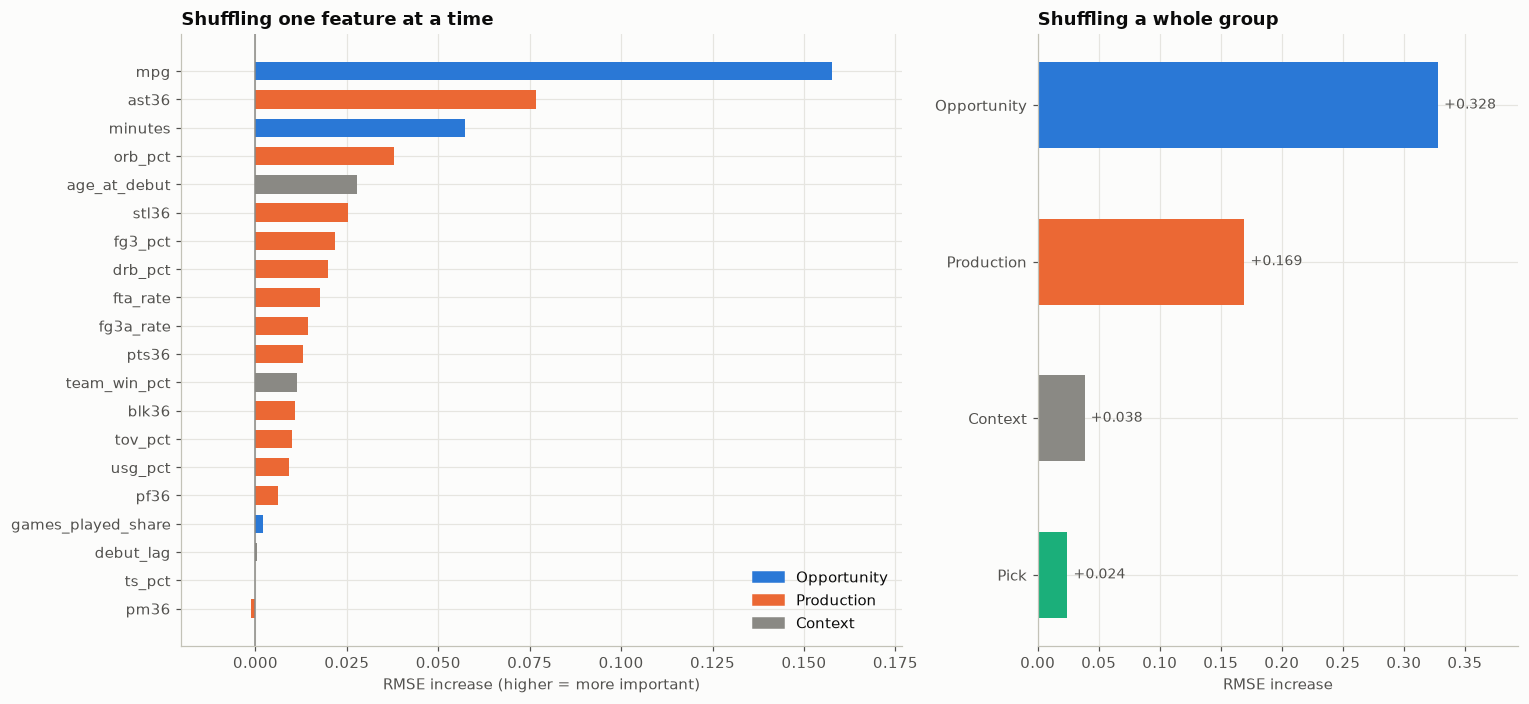

,mean,std
set,,
Opportunity,0.3279,0.1243
Production,0.1693,0.0875
mpg,0.1577,0.0991
ast36,0.0767,0.0628
minutes,0.0573,0.0639
Context,0.0384,0.0296
orb_pct,0.0379,0.0433
age_at_debut,0.0278,0.0254
stl36,0.0254,0.0393


In [3]:
group_of = {f: g for g, cols in md.GROUPS.items() for f in cols}
group_color = {"Context": NEUTRAL, "Opportunity": BLUE, "Production": ORANGE, "Pick": AQUA}

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
ax.barh(single_imp.index, single_imp["mean"], height=0.65,
        color=[group_color[group_of[f]] for f in single_imp.index])
ax.axvline(0, color=NEUTRAL, linewidth=1)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=group_color[g], label=g)
                   for g in ["Opportunity", "Production", "Context"]], loc="lower right")
ax.margins(x=0.12)
ax.set(title="Shuffling one feature at a time", xlabel="RMSE increase (higher = more important)")

ax = axes[1]
ax.barh(group_imp.index, group_imp["mean"], height=0.55,
        color=[group_color[g] for g in group_imp.index])
for y, v in enumerate(group_imp["mean"]):
    ax.annotate(f"+{v:.3f}", (v, y), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK_2)
ax.margins(x=0.2)
ax.set(title="Shuffling a whole group", xlabel="RMSE increase")
plt.tight_layout()
plt.show()
importance.round(4).sort_values("mean", ascending=False)

**What to look for:** on the left, how much the top features stand out from the
rest; bars near 0 (or below) are features the model barely uses. On the right,
the group comparison is the fair one: it shows how much the model loses without
each *kind* of information. Compare Opportunity with Production: the ablation in
02 said opportunity carries most of the gain; this checks it from another angle.

## 2. What shape does each effect have? (partial dependence)

Fit the model on the whole development set, then for one feature: set it to a
value **for every player**, predict, and average. Repeat across the feature's
range. The curve shows how the prediction moves with that feature, everything
else as it was.

**Caveat:** for features tied to others (e.g. minutes per game and total
minutes), moving one alone creates combinations that don't exist in real life,
so read those curves as rough directions, not exact values.

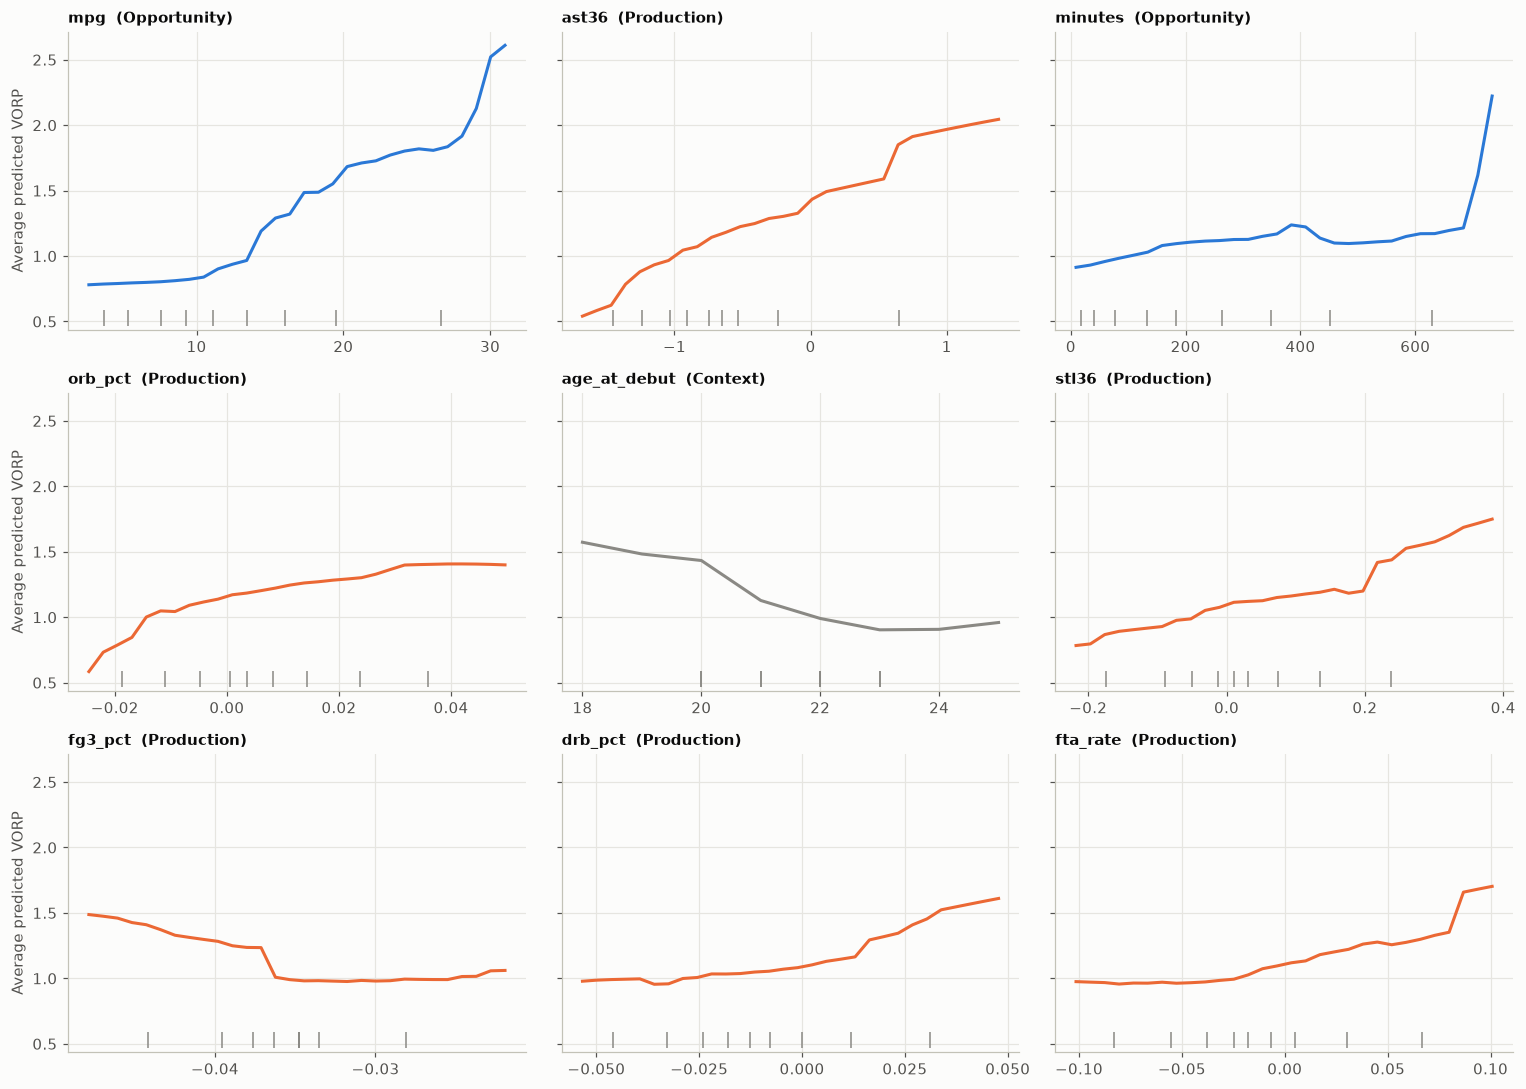

In [4]:
full_model = md.ensemble().fit(dev[md.ALL], dev[m.TARGET])
top = single_imp.sort_values("mean", ascending=False).index[:9].tolist()

fig, axes = plt.subplots(3, 3, figsize=(14, 10), sharey=True)
for ax, f in zip(axes.flat, top):
    pd_res = partial_dependence(full_model, dev[md.ALL], [f], kind="average",
                                grid_resolution=30, percentiles=(0.05, 0.95))
    ax.plot(pd_res["grid_values"][0], pd_res["average"][0], color=group_color[group_of[f]])
    deciles = dev[f].quantile(np.linspace(0.1, 0.9, 9))
    # ticks at the bottom of each panel (x in data units, y in axes units)
    ax.plot(deciles, [0.04] * len(deciles), "|", color=NEUTRAL, markersize=10,
            transform=ax.get_xaxis_transform())
    ax.locator_params(axis="x", nbins=5)
    ax.set_title(f"{f}  ({group_of[f]})", fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel("Average predicted VORP")
plt.tight_layout()
plt.show()

**What to look for:** the direction and the shape. A steady climb means "more is
better" all the way; a curve that flattens means the benefit saturates; a U means
both extremes are good. The ticks at the bottom mark where the deciles of real
players are: the curve is only trustworthy where there are players.

## 3. Do early minutes mean the same for every pick?

The same exercise for minutes per game, but with the pick fixed at 3, 15 and 45
for everyone. Total minutes move together with minutes per game (games played
kept as they were), so the combinations stay realistic.

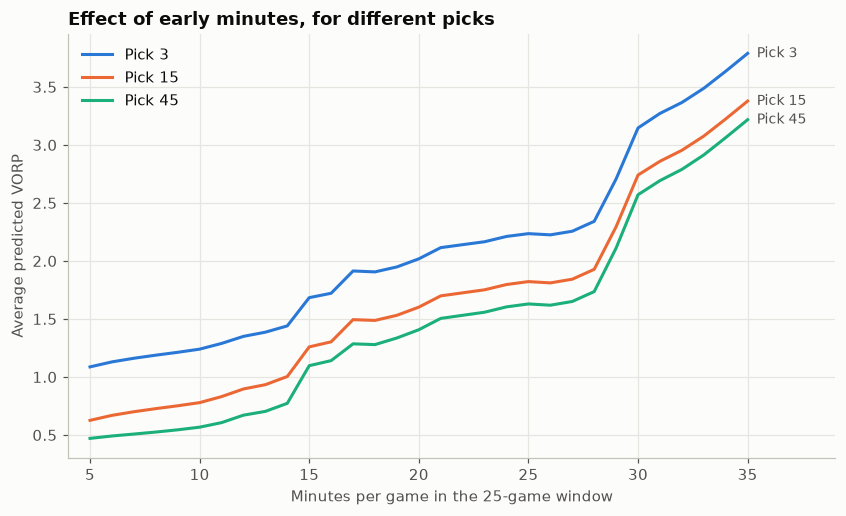

Pick 3: 10 -> 30 mpg raises the prediction by +1.91
Pick 15: 10 -> 30 mpg raises the prediction by +1.96
Pick 45: 10 -> 30 mpg raises the prediction by +2.00


In [5]:
grid = np.linspace(5, 35, 31)
games = dev["games_played"]

fig, ax = plt.subplots(figsize=(9, 5))
curves = {}
for pick, color in zip([3, 15, 45], [BLUE, ORANGE, AQUA]):
    X = dev[md.ALL].copy()
    X["log_pick"] = np.log(pick)
    X["log_pick2"] = np.log(pick) ** 2
    preds = []
    for v in grid:
        X["mpg"] = v
        X["minutes"] = v * games
        preds.append(full_model.predict(X).mean())
    curves[pick] = np.array(preds)
    ax.plot(grid, preds, color=color, label=f"Pick {pick}")
    ax.annotate(f"Pick {pick}", (grid[-1], preds[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK_2)
ax.set_xlim(4, 39)
ax.set(title="Effect of early minutes, for different picks",
       xlabel="Minutes per game in the 25-game window", ylabel="Average predicted VORP")
ax.legend(loc="upper left")
plt.show()

for pick, c in curves.items():
    print(f"Pick {pick}: 10 -> 30 mpg raises the prediction by {c[np.argmin(abs(grid - 30))] - c[np.argmin(abs(grid - 10))]:+.2f}")

**What to look for:** parallel lines mean minutes add the same value whatever the
pick (the effects simply stack). Lines that spread apart mean minutes matter more
for some picks than others (an interaction, which only the boosting half can
learn).

## 4. Player stories

Out-of-fold predictions only. For each player: the baseline's error vs the
model's error. **Improvement** = how much closer the model got than the pick
alone.

In [6]:
players = dev.assign(
    baseline_pred=base_oof, model_pred=model_oof,
    baseline_err=(dev[m.TARGET] - base_oof).abs(),
    model_err=(dev[m.TARGET] - model_oof).abs(),
)
players["improvement"] = players["baseline_err"] - players["model_err"]
share_better = (players["improvement"] > 0).mean()
print(f"The model is closer than the baseline for {share_better:.0%} of players")

COLS = ["player_name", "draft_year", "pick", "age_at_debut", "mpg", "games_played_share",
        "ts_pct", "usg_pct", "stl36", m.TARGET, "baseline_pred", "model_pred", "improvement"]
print("\nWhere the first 25 games corrected the pick the most")
display(players.nlargest(10, "improvement")[COLS].round(2))

The model is closer than the baseline for 61% of players

Where the first 25 games corrected the pick the most


,player_name,draft_year,pick,age_at_debut,mpg,games_played_share,ts_pct,usg_pct,stl36,target_vorp,baseline_pred,model_pred,improvement
239,Chris Paul,2005,4,20.0,36.76,1.00,-0.01,0.02,0.74,19.2,2.71,6.67,3.96
641,Anthony Bennett,2013,1,20.0,10.10,0.80,-0.12,-0.02,0.10,0.0,5.63,1.70,3.93
291,Andrea Bargnani,2006,1,21.0,20.12,0.96,-0.03,0.03,-0.29,1.6,5.39,1.67,3.72
390,Derrick Rose,2008,1,20.0,39.24,1.00,-0.03,0.01,-0.07,9.6,5.28,8.84,3.56
50,Kwame Brown,2001,1,19.0,13.50,0.80,-0.06,-0.02,-0.20,0.3,5.45,2.01,3.44
594,Damian Lillard,2012,6,22.0,37.92,1.00,0.00,0.03,-0.08,9.2,2.28,5.41,3.13
506,Eric Bledsoe,2010,18,21.0,28.32,1.00,-0.03,-0.03,0.12,4.0,1.03,3.95,2.92
383,Marc Gasol,2007,48,24.0,28.68,1.00,0.03,-0.02,-0.18,5.9,0.43,3.29,2.87
76,Jamaal Tinsley,2001,27,23.0,32.20,1.00,-0.06,0.00,0.62,3.6,0.69,3.68,2.83
145,Carmelo Anthony,2003,3,19.0,35.28,1.00,-0.04,0.05,0.14,6.0,2.95,5.65,2.71


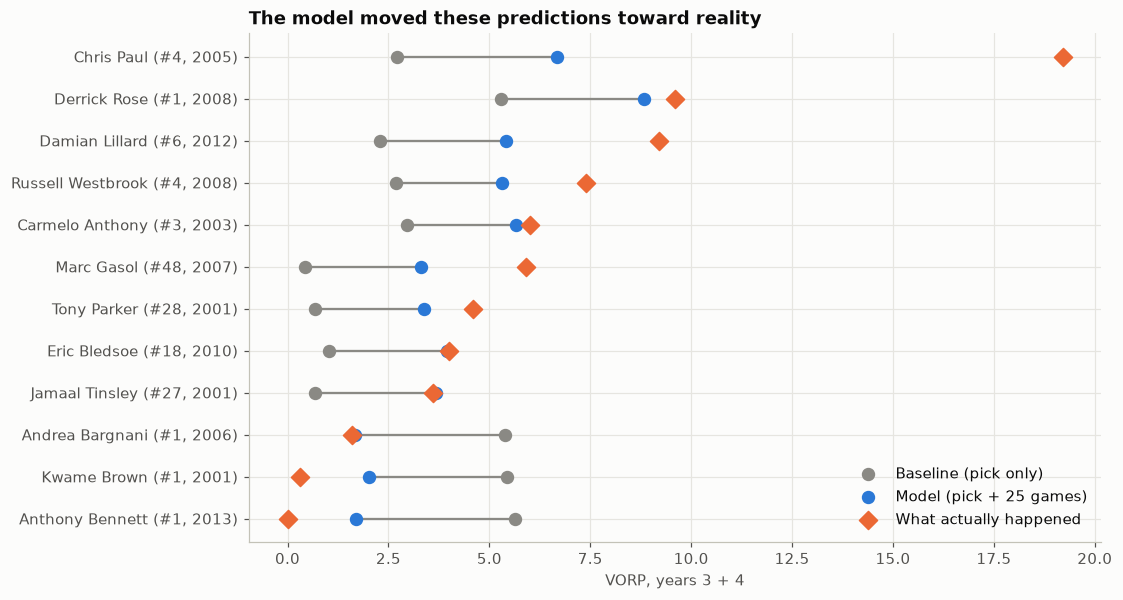

In [7]:
show = players.nlargest(12, "improvement").sort_values(m.TARGET, ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
for i, (_, r) in enumerate(show.iterrows()):
    ax.plot([r["baseline_pred"], r["model_pred"]], [i, i], color=NEUTRAL, linewidth=1.5, zorder=1)
    ax.scatter(r["baseline_pred"], i, s=60, color=NEUTRAL, zorder=2)
    ax.scatter(r["model_pred"], i, s=60, color=BLUE, zorder=3)
    ax.scatter(r[m.TARGET], i, s=70, marker="D", color=ORANGE, zorder=4)
ax.set_yticks(range(len(show)), [f"{r['player_name']} (#{int(r['pick'])}, {int(r['draft_year'])})"
                                 for _, r in show.iterrows()])
ax.invert_yaxis()
ax.scatter([], [], s=60, color=NEUTRAL, label="Baseline (pick only)")
ax.scatter([], [], s=60, color=BLUE, label="Model (pick + 25 games)")
ax.scatter([], [], s=70, marker="D", color=ORANGE, label="What actually happened")
ax.legend(loc="lower right")
ax.set(title="The model moved these predictions toward reality", xlabel="VORP, years 3 + 4")
plt.show()

**What to look for:** the blue dot moving from the grey one toward the orange
diamond. Note the direction: some are busts the model pulled *down* (low early
minutes or poor efficiency for a top pick), others steals it pushed *up*.

In [8]:
print("Where the model still missed the most (biggest errors)")
display(players.nlargest(10, "model_err")[COLS].round(2))
print("Where the model made things worse than the pick alone")
display(players.nsmallest(8, "improvement")[COLS].round(2))

Where the model still missed the most (biggest errors)


,player_name,draft_year,pick,age_at_debut,mpg,games_played_share,ts_pct,usg_pct,stl36,target_vorp,baseline_pred,model_pred,improvement
239,Chris Paul,2005,4,20.0,36.76,1.00,-0.01,0.02,0.74,19.2,2.71,6.67,3.96
143,LeBron James,2003,1,19.0,40.12,1.00,-0.03,0.04,-0.04,17.5,4.48,6.60,2.11
296,Brandon Roy,2006,6,22.0,27.20,0.20,-0.05,0.01,-0.15,10.1,2.20,1.34,-0.86
344,Kevin Durant,2007,2,19.0,33.32,1.00,-0.04,0.07,0.04,12.8,3.89,4.31,0.43
147,Dwyane Wade,2003,5,22.0,36.22,0.92,-0.03,0.03,0.19,12.0,2.33,4.27,1.94
498,Paul George,2010,10,20.0,16.38,0.32,-0.06,-0.02,0.03,9.4,1.59,1.93,0.34
621,Draymond Green,2012,35,22.0,14.72,1.00,-0.11,-0.04,0.40,8.8,0.57,1.40,0.84
654,Giannis Antetokounmpo,2013,15,19.0,19.40,0.80,-0.00,-0.04,0.01,9.6,1.13,2.48,1.35
41,Michael Redd,2000,43,21.0,3.00,0.20,-0.05,-0.00,0.07,6.9,0.43,0.40,-0.03
650,Michael Carter-Williams,2013,11,22.0,36.80,0.60,-0.04,0.03,1.02,0.2,1.44,6.62,-5.18


Where the model made things worse than the pick alone


,player_name,draft_year,pick,age_at_debut,mpg,games_played_share,ts_pct,usg_pct,stl36,target_vorp,baseline_pred,model_pred,improvement
650,Michael Carter-Williams,2013,11,22.0,36.80,0.60,-0.04,0.03,1.02,0.2,1.44,6.62,-5.18
442,Tyreke Evans,2009,4,20.0,36.00,0.96,-0.01,0.04,0.28,2.7,2.68,7.63,-4.91
524,Landry Fields,2010,39,22.0,31.36,1.00,0.03,-0.05,0.05,0.2,0.53,4.07,-3.54
99,Yao Ming,2002,1,22.0,25.44,1.00,0.07,0.01,-0.46,6.0,5.60,2.42,-3.18
292,LaMarcus Aldridge,2006,2,21.0,16.96,0.92,-0.02,-0.02,-0.21,4.8,3.97,0.96,-3.01
392,O.J. Mayo,2008,3,21.0,37.60,1.00,0.01,0.05,0.03,2.0,3.14,6.07,-2.93
444,Jonny Flynn,2009,6,20.0,29.24,1.00,-0.02,0.04,0.22,-0.3,2.15,4.56,-2.40
192,Ben Gordon,2004,3,21.0,23.16,1.00,-0.01,0.06,-0.12,4.7,3.10,0.92,-2.18


**What to look for:** are the biggest misses players whose first 25 games
genuinely looked ordinary (late bloomers, the "invisible" part of the outcome),
or players the model should have caught? The "made it worse" list shows the
price of using the early games: rookies who looked bad early but became good
(or the reverse).

## 5. Bias checks

Average error (actual - predicted, out-of-fold) by draft class, age at debut and
pick segment. Ideally every bar sits near 0: no group is systematically over- or
under-predicted. A drift across draft classes would matter for the walk-forward
test, which predicts *newer* classes.

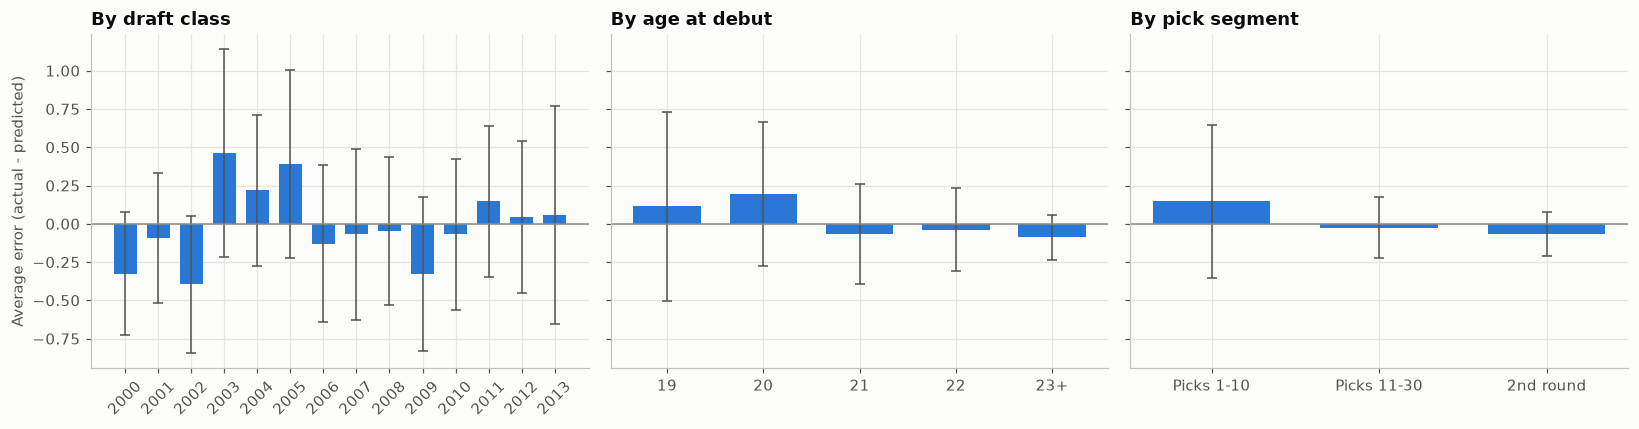

In [9]:
players["resid"] = players[m.TARGET] - players["model_pred"]
players["age_group"] = pd.cut(players["age_at_debut"], [0, 19.5, 20.5, 21.5, 22.5, 30],
                              labels=["19", "20", "21", "22", "23+"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col, title in [(axes[0], "draft_year", "By draft class"),
                       (axes[1], "age_group", "By age at debut"),
                       (axes[2], "segment", "By pick segment")]:
    g = players.groupby(col, observed=True)["resid"].agg(["mean", "sem", "size"])
    if col == "segment":
        g = g.reindex(m.SEGMENTS)
    x = [str(i) for i in g.index]
    ax.bar(x, g["mean"], color=BLUE, width=0.7)
    ax.errorbar(x, g["mean"], yerr=1.96 * g["sem"], fmt="none", ecolor=INK_2,
                elinewidth=1, capsize=3)
    ax.axhline(0, color=NEUTRAL, linewidth=1)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=45 if col == "draft_year" else 0)
axes[0].set_ylabel("Average error (actual - predicted)")
plt.tight_layout()
plt.show()

**What to look for:** bars whose error whiskers (95% intervals) clearly miss 0.
Positive = the model under-predicts that group; negative = over-predicts. With
~50 players per class, single-class swings are expected; a *trend* across
classes is what would be worrying.